In [1]:
import hashlib
import imagehash
from pathlib import Path
from collections import Counter , defaultdict
import shutil

import random
import cv2 as cv
from PIL import Image
import matplotlib.pyplot as plt

In [2]:
data_path=Path(r'/mnt/d/dataset/helmet_dataset')

## Keep only helmet annotations and remap the helmet class ID from 1 to 0 in the train and test label files.

In [3]:
for split in ['train','test']:
    label_dir=data_path/split/'labels'
    for label_file in label_dir.glob('*.txt'):

        new_lines=[]
        for lines in label_file.read_text().splitlines():
            part=lines.split()
            class_id=int(part[0])

            if class_id==1:
                part[0]='0'
                new_lines.append(' '.join(part))

        label_file.write_text('\n'.join(new_lines))

## Count and display the number of annotations for each class in the train and test label files after keeping only helmet class

In [3]:
for split in ['train' , 'test']:
    label_dir=data_path/split/'labels'
    class_count=Counter()

    for label_file in label_dir.glob('*.txt'):
        for line in label_file.read_text().splitlines():
            class_id=int(line.split()[0])

            class_count[class_id] += 1

    print(split)
    print(class_count)

train
Counter({0: 14884})
test
Counter({0: 4863})


## Validate YOLO bounding-box coordinates and dimensions, and report any values outside the valid range [0, 1]

In [4]:
invalid_box=[]

for split in ['train' , 'test']:
    label_dir=data_path/split/'labels'

    for label_file in label_dir.glob('*.txt'):
        for line in label_file.read_text().splitlines():
            part=line.split()
            x,y,w,h=map(float ,part[1:])
            if not (0<= x <=1):
                invalid_box.append((split , label_file.name , 'invalid_x'))
            if not (0<= y <=1):
                invalid_box.append((split , label_file.name , 'invalid_y'))
            if not (0<= w <=1):
                invalid_box.append((split , label_file.name , 'invalid_w'))
            if not (0<= h <=1):
                invalid_box.append((split , label_file.name , 'invalid_h'))


if invalid_box:
    for item in invalid_box:
        print(item)

else:
    print('invalid item dose not exist')

invalid item dose not exist


## MD5 → exact duplicate detection
## pHash → visually similar image detection

## Detect exact duplicate images in the training set by grouping files with identical MD5 hashes.

In [4]:
images_dir = data_path / 'train' / 'images'
hash_to_images = defaultdict(list)

for image_path in images_dir.glob('*'):

    if image_path.suffix.lower() not in ['.jpg', '.jpeg', '.png']:
        continue

    file_hash = hashlib.md5(image_path.read_bytes()).hexdigest()
    hash_to_images[file_hash].append(image_path)


duplicate_groups = [paths for paths in hash_to_images.values() if len(paths) > 1]
print("Number of duplicate groups:", len(duplicate_groups))

Number of duplicate groups: 0


## Compute perceptual hashes to identify visually similar images in the training set.

In [5]:
hashes = {}

for image_path in images_dir.glob('*'):

    if image_path.suffix.lower() not in ['.jpg', '.jpeg', '.png']:
        continue

    image = Image.open(image_path)
    hashes[image_path] = imagehash.phash(image)

## Find pairs of visually similar images using the Hamming distance between their perceptual hashes

In [6]:
near_duplicates = []
image_paths = list(hashes.keys())

for i in range(len(image_paths)):
    for j in range(i + 1, len(image_paths)):
        distance = hashes[image_paths[i]] - hashes[image_paths[j]]

        if distance <= 5:
            near_duplicates.append((image_paths[i], image_paths[j], distance))
print("Near-duplicate pairs:", len(near_duplicates))

Near-duplicate pairs: 104


In [6]:
for image1, image2, distance in near_duplicates[:20]:
    print(f"distance={distance:2d} | "f"{image1.name} <-> {image2.name}")

distance= 2 | 000075_jpg.rf.43c5b89baa229e8fa8b82846a79f34f3.jpg <-> 004431_jpg.rf.b3cf808781d5ae711ad7515d3eba317c.jpg
distance= 0 | 000105_jpg.rf.7ef7bab5da788550f13f7c684015548b.jpg <-> 001383_jpg.rf.8a9e4b2bea69afa03231916f8515a0bb.jpg
distance= 2 | 000202_jpg.rf.afb187a78cf40a978f849908794156de.jpg <-> 001412_jpg.rf.3ca01911105f89a5f3372bc59bbd7ae0.jpg
distance= 2 | 000202_jpg.rf.afb187a78cf40a978f849908794156de.jpg <-> 003190_jpg.rf.d1407badd856b2786ca029296439d793.jpg
distance= 4 | 000217_jpg.rf.7673bae0f0d6100f62e0fcae402b01b6.jpg <-> 000372_jpg.rf.1308beb0a405c3452a5ebda9b9f94470.jpg
distance= 0 | 000343_jpg.rf.a3b44a7914288e37dfb202824c51e090.jpg <-> 003347_jpg.rf.789ec5ccb1a325a980ca92b5e710aa18.jpg
distance= 2 | 000344_jpg.rf.b12e7c5c764f6e4cd1cd44513043ad67.jpg <-> 004249_jpg.rf.815c3b1ddc34694cd69ccf6e4fc5961d.jpg
distance= 2 | 000364_jpg.rf.9a96853ecdf5f11e21c351bd7dd6f226.jpg <-> 000641_jpg.rf.b042923a28739e1e81ef9ab66274e9fe.jpg
distance= 2 | 000397_jpg.rf.f1443b63f7ec

## Build a graph of visually similar images by connecting each near-duplicate pair

In [7]:
graph = defaultdict(set)

for image1, image2, distance in near_duplicates:
    graph[image1].add(image2)
    graph[image2].add(image1)

## Group connected near-duplicate images using depth-first search (DFS) on the similarity graph.

In [8]:
visited = set()
duplicate_groups = []

for image in graph:
    if image in visited:
        continue

    group = set()
    stack = [image]

    while stack:
        current = stack.pop()

        if current in visited:
            continue

        visited.add(current)
        group.add(current)

        for neighbor in graph[current]:

            if neighbor not in visited:
                stack.append(neighbor)

    duplicate_groups.append(group)

print("Number of near-duplicate groups:", len(duplicate_groups))


group_sizes = sorted( [len(group) for group in duplicate_groups], reverse=True)
print("Group sizes:")
print(group_sizes)

Number of near-duplicate groups: 93
Group sizes:
[4, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]


## Filter duplicate groups containing 3 or more images and print their filenames.

In [9]:
large_groups = [ group for group in duplicate_groups if len(group) >= 3]
print("Groups with 3+ images:", len(large_groups))

for i, group in enumerate(large_groups, 1):
    print(f"\nGroup {i} ({len(group)} images):")

    for image_path in group:
        print(image_path.name)

Groups with 3+ images: 5

Group 1 (3 images):
003190_jpg.rf.d1407badd856b2786ca029296439d793.jpg
001412_jpg.rf.3ca01911105f89a5f3372bc59bbd7ae0.jpg
000202_jpg.rf.afb187a78cf40a978f849908794156de.jpg

Group 2 (3 images):
000397_jpg.rf.f1443b63f7ecbdedf4a8319f6e987c29.jpg
003433_jpg.rf.d678bc593c039b47adc7a9ff5fcc60ee.jpg
002637_jpg.rf.9952a65cf2b65a9e977939b1970f531d.jpg

Group 3 (4 images):
002461_jpg.rf.231f3fe1482f2174f419c4ef9734b0c6.jpg
004805_jpg.rf.fe8f64395300e0218e67f2c54eb24714.jpg
000926_jpg.rf.36abbee996ba5bc533cdc3718166ef7c.jpg
004353_jpg.rf.485e42065a9bd464298f861023a178f9.jpg

Group 4 (3 images):
002459_jpg.rf.dfa0a19456770f3d4d285d06e2256a14.jpg
003230_jpg.rf.07dfc45b58e260643da000ee98e30c4b.jpg
001761_jpg.rf.e8b2d1e1d3cc37ac51863ce647d4f932.jpg

Group 5 (3 images):
002216_jpg.rf.2cb4a2b4bee5df4564f23a3cd683ffab.jpg
002596_jpg.rf.687167c0b68deec7b2b7b9f17b01d009.jpg
004800_jpg.rf.dea4ecf0aff5a3b9fbc891cd3536313f.jpg


## Visualize up to four images from each large near-duplicate group for manual inspection.

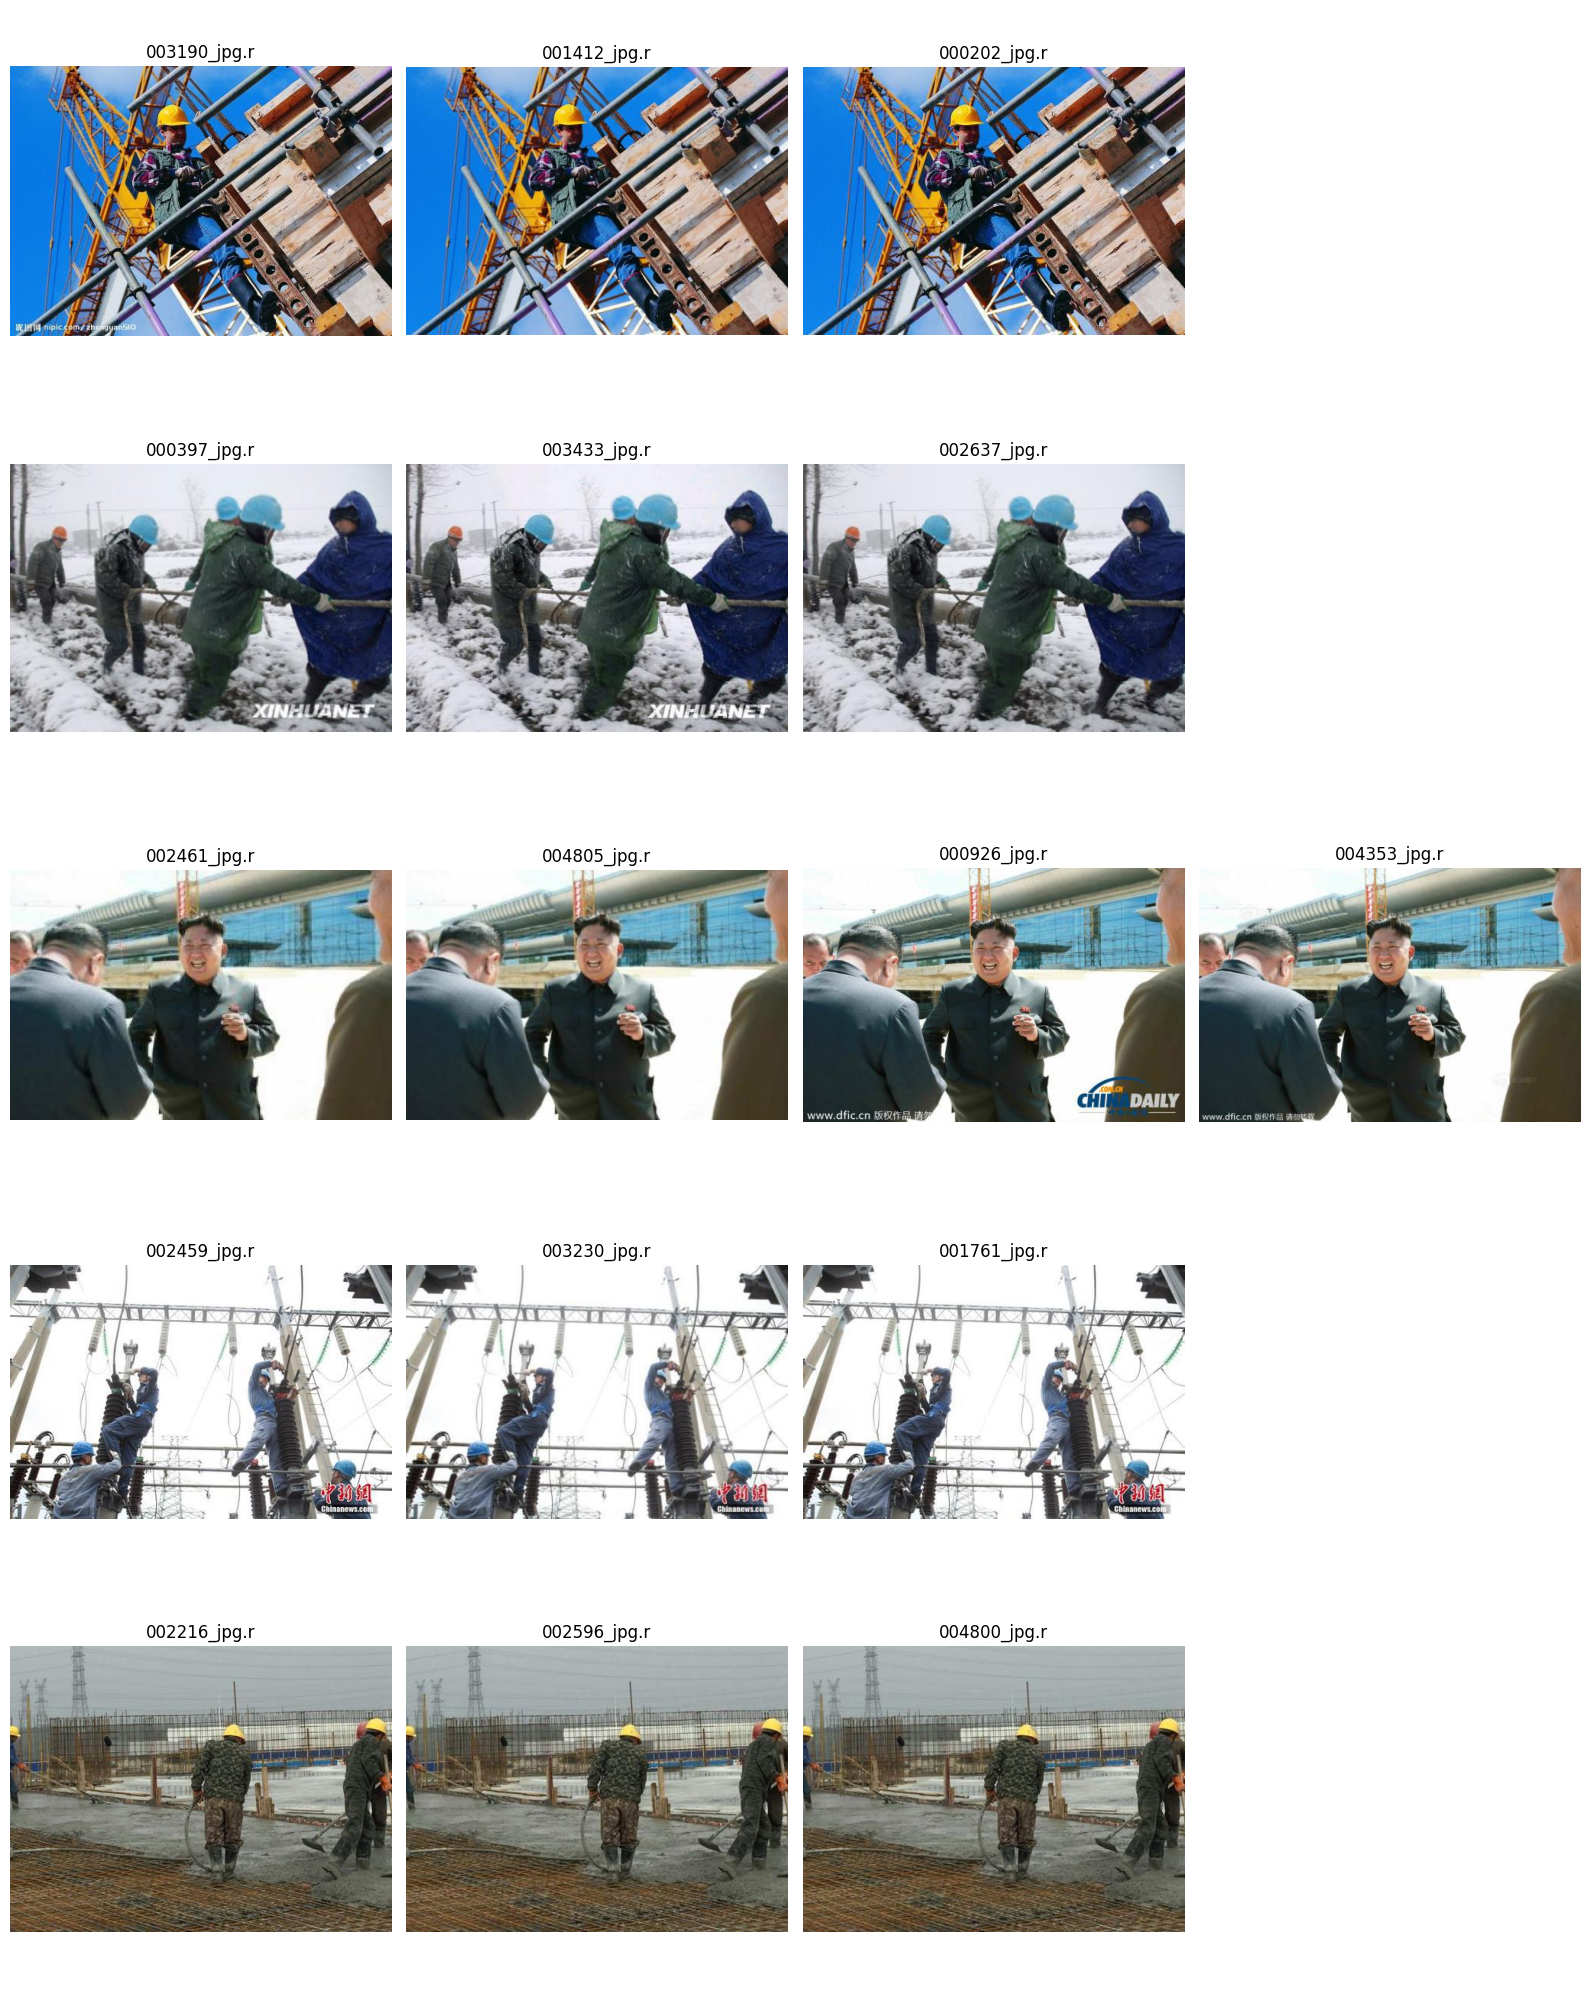

In [10]:
fig, axes = plt.subplots( len(large_groups), 4, figsize=(16, 4 * len(large_groups)))

for row, group in enumerate(large_groups):
    group = list(group)

    for col in range(4):
        ax = axes[row, col]

        if col < len(group):
            image_path = group[col]
            image = Image.open(image_path)

            ax.imshow(image)
            ax.set_title(image_path.name[:12])
            ax.axis('off')

        else:
            ax.axis('off')

plt.tight_layout()
plt.show()

## Count images involved in near-duplicate groups and calculate the number of independent training images.

In [11]:
duplicate_images = set()

for group in duplicate_groups:
    duplicate_images.update(group)

print("Images in duplicate groups:", len(duplicate_images))
print("Total train images:", len(image_paths))
print( "Independent images:", len(image_paths) - len(duplicate_images))

Images in duplicate groups: 192
Total train images: 5269
Independent images: 5077


## Create leakage-safe split units by keeping near-duplicate groups together and treating independent images as individual units.

In [12]:
all_grouped_images = set().union(*duplicate_groups) if duplicate_groups else set()

independent_images = [ image_path for image_path in image_paths
                       if image_path not in all_grouped_images]

split_units = duplicate_groups + [{image_path} for image_path in independent_images]

print("Number of duplicate groups:", len(duplicate_groups))
print("Number of independent images:", len(independent_images))
print("Total split units:", len(split_units))

Number of duplicate groups: 93
Number of independent images: 5077
Total split units: 5170


## Randomly shuffle split units and select groups for validation while keeping near-duplicates together.

In [13]:
random.seed(42)
random.shuffle(split_units)

total_images = len(image_paths)
target_valid_images = round(total_images * 0.20)

print("Total images:", total_images)
print("Target validation images:", target_valid_images)

valid_groups = []
valid_count = 0

for group in split_units:
    group_size = len(group)

    if valid_count + group_size <= target_valid_images:
        valid_groups.append(group)
        valid_count += group_size

valid_images = set().union(*valid_groups) if valid_groups else set()
train_images = set(image_paths) - valid_images

Total images: 5269
Target validation images: 1054


In [14]:
print("Train images:", len(train_images))
print("Valid images:", len(valid_images))
print("Total:", len(train_images) + len(valid_images))

Train images: 4215
Valid images: 1054
Total: 5269


## Create the validation directories and copy each selected image with its corresponding YOLO label.

In [16]:
valid_image_dir=data_path/'valid'/'images'
valid_label_dir=data_path/'valid'/'labels'

valid_image_dir.mkdir(parents=True , exist_ok=True)
valid_label_dir.mkdir(parents=True , exist_ok=True)

for image_path in list(valid_images):
    label_path=data_path/'train'/'labels'/f'{image_path.stem}.txt'

    shutil.copy2(image_path , valid_image_dir/image_path.name)
    shutil.copy2(label_path , valid_label_dir/label_path.name)

In [17]:
print("Original train images:", len(image_paths))
print("Validation images:", len(valid_images))
print("Remaining train images:", len(train_images))
print("Total:", len(valid_images) + len(train_images))

Original train images: 5269
Validation images: 1054
Remaining train images: 4215
Total: 5269


In [20]:
over_lap=train_images & valid_images
print('train/validation overlap:', len(over_lap))

train/validation overlap: 0


## Check whether every validation image has its corresponding original label file in the training directory

In [21]:
missing_labels = []

for image_path in valid_images:
    label_path = data_path / "train" / "labels" / f"{image_path.stem}.txt"

    if not label_path.exists():
        missing_labels.append(image_path.name)

print("Missing validation labels:", len(missing_labels))

Missing validation labels: 0


## Check whether every validation image has a corresponding label file in the validation directory

In [22]:
missing_labels = []

for image_path in valid_images:
    label_path = data_path / "valid" / "labels" / f"{image_path.stem}.txt"

    if not label_path.exists():
        missing_labels.append(image_path.name)

print("Missing validation labels:", len(missing_labels))

Missing validation labels: 0


In [24]:
valid_image_files = list(valid_image_dir.glob("*"))
valid_label_files = list(valid_label_dir.glob("*.txt"))

print("Validation images:", len(valid_image_files))
print("Validation labels:", len(valid_label_files))

Validation images: 1054
Validation labels: 1054


## Check for near-duplicate groups that are incorrectly split between the training and validation sets

In [25]:
leaked_groups = []

for group in duplicate_groups:
    train_part = group & train_images
    valid_part = group & valid_images

    if train_part & valid_part:
        leaked_groups.append(group)

print("Leaked duplicate groups:", len(leaked_groups))

Leaked duplicate groups: 0


## Remove validation images and their corresponding labels from the original training directories

In [26]:
for image_path in valid_images:

    train_image = image_path
    train_label = data_path / "train" / "labels" / f"{image_path.stem}.txt"

    train_image.unlink()
    train_label.unlink()

## Count the actual image files in the training and validation directories after splitting

In [27]:
actual_train_images = list((data_path / "train" / "images").glob("*"))
actual_valid_images = list((data_path / "valid" / "images").glob("*"))

print("Actual train images:", len(actual_train_images))
print("Actual valid images:", len(actual_valid_images))

Actual train images: 4215
Actual valid images: 1054
